# Location feature engineering:

The purpose of this notebook is to enrich the existing data with location-specific amenities such as nearby school, mall, and MRT. These can affect the rent, so we add them to our main train data before we proceed with any technique.

This notebook starts from the main rent data's `TOWN`, `BLOCK`, and `STREET` fields and enriches each row with information from `auxiliary/sg-hdb-block.csv`, `auxiliary/sg-mrt-stations.csv`, `auxiliary/sg-shopping-malls.csv` and `auxiliary/sg-schools.csv`.

The workflow is target-independent: it does not use `MONTHLY_RENT` to construct these features.

## 1. Imports and paths

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd()

AUXILIARY_DIR = PROJECT_ROOT / "auxiliary"
TRAIN_PATH = PROJECT_ROOT / "train.csv"
TEST_PATH = PROJECT_ROOT / "test.csv"
PLOTS_DIR = PROJECT_ROOT / "plots"

HDB_PATH = AUXILIARY_DIR / "sg-hdb-block.csv"
MRT_PATH = AUXILIARY_DIR / "sg-mrt-stations.csv"
SCHOOL_PATH = AUXILIARY_DIR / "sg-schools.csv"
MALLS_PATH = AUXILIARY_DIR / "sg-shopping-malls.csv"

print(f"Project root: {PROJECT_ROOT}")

Project root: /Users/apple/Documents/modules/CS5228/project repo/cs5228_team26


## 2. Load the main data and HDB block reference

First we enrich train data with LATITUTE, LONGITUDE values mapped from HDB block data. 

Followed by that, we add three main derived features to the data:
- Nearest MRT station distance, 
- Nearest School distance,
- Nearest Mall distance

We can argue that proximity to amenities is a big factor in choosing a house, thus increasing the demand and rent of flats within reach of a school, MRT and mall.

In [3]:
train = pd.read_csv(TRAIN_PATH, dtype={"BLOCK": "string"})
test = pd.read_csv(TEST_PATH, dtype={"BLOCK": "string"})
hdb = pd.read_csv(
    HDB_PATH,
    dtype={"BLOCK": "string", "POSTAL_CODE": "string"},
)

print(f"Train shape: {train.shape}")
print(f"Test shape:  {test.shape}")
print(f"HDB shape:   {hdb.shape}")
print("\nMain columns:", list(train.columns))
print("HDB columns: ", list(hdb.columns))

Train shape: (150000, 11)
Test shape:  (50000, 10)
HDB shape:   (9464, 11)

Main columns: ['RENT_APPROVAL_DATE', 'TOWN', 'BLOCK', 'STREET', 'FLAT_TYPE', 'FLAT_MODEL', 'FLOOR_AREA_SQM', 'FURNISHED', 'LEASE_COMMENCE_DATE', 'FEE', 'MONTHLY_RENT']
HDB columns:  ['TOWN', 'BLOCK', 'STREET', 'POSTAL_CODE', 'LATITUDE', 'LONGITUDE', 'MAX_FLOOR', 'YEAR_COMPLETED', 'SUBZONE', 'PLANNING_AREA', 'REGION']


## 3. Normalize location keys to map rows rom HDB data to train data

The source files differ in capitalization and may contain inconsistent whitespace or punctuation, as we saw in EDA file. We create normalized keys while retaining the original columns.

The primary key is `town + block + street`, we use that do map both the csv files.

In [4]:
def normalize_key_text(values: pd.Series) -> pd.Series:
    """Normalize text for matching, without changing the source column."""
    return (
        values.astype("string")
        .fillna("")
        .str.strip()
        .str.lower()
        .str.replace(r"[^a-z0-9]+", " ", regex=True)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )


def add_location_keys(data: pd.DataFrame) -> pd.DataFrame:
    result = data.copy()
    for column in ["TOWN", "BLOCK", "STREET"]:
        result[f"{column}_KEY"] = normalize_key_text(result[column])
    result["LOCATION_KEY"] = (
        result["TOWN_KEY"] + "|"
        + result["BLOCK_KEY"] + "|"
        + result["STREET_KEY"]
    )
    return result

train_keys = add_location_keys(train)
test_keys = add_location_keys(test)
hdb_keys = add_location_keys(hdb)

duplicate_location_keys = hdb_keys[
    hdb_keys.duplicated("LOCATION_KEY", keep=False)
]["LOCATION_KEY"].nunique()
print(f"HDB duplicate normalized location keys: {duplicate_location_keys}")
print("Example normalized keys:")
display(train_keys[["TOWN", "BLOCK", "STREET", "LOCATION_KEY"]].head())

HDB duplicate normalized location keys: 0
Example normalized keys:


,TOWN,BLOCK,STREET,LOCATION_KEY
0,punggol,604a,punggol road,punggol|604a|punggol road
1,sengkang,290c,compassvale crescent,sengkang|290c|compassvale crescent
2,queenstown,5,ghim moh road,queenstown|5|ghim moh road
3,sengkang,436b,fernvale road,sengkang|436b|fernvale road
4,sembawang,467b,admiralty drive,sembawang|467b|admiralty drive


In [5]:
display(hdb.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
TOWN,9464,26,tampines,761,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BLOCK,9464,2735,111,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
STREET,9464,576,yishun ring road,140,NaN,NaN,NaN,NaN,NaN,NaN,NaN
POSTAL_CODE,9464,9180,NIL,285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LATITUDE,9464.0,NaN,NaN,NaN,1.366731,0.041516,1.27038,1.338893,1.364216,1.392729,1.457071
LONGITUDE,9464.0,NaN,NaN,NaN,103.841135,0.074127,103.685228,103.774158,103.846489,103.899927,103.987805
MAX_FLOOR,9464.0,NaN,NaN,NaN,14.294696,5.989292,-1.0,12.0,13.0,16.0,50.0
YEAR_COMPLETED,9464.0,NaN,NaN,NaN,1989.84161,69.138523,-1.0,1984.0,1991.0,1999.0,2021.0
SUBZONE,9464,156,tampines east,414,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PLANNING_AREA,9464,31,tampines,761,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Build safe HDB lookup tables

Rows with ambiguous normalized keys are excluded from lookup rather than assigning an arbitrary block.

In [6]:
# columns of interest from HDB csv file, rest are dropped 
HDB_SOURCE_COLUMNS = [
    "LATITUDE",
    "LONGITUDE",
    "YEAR_COMPLETED",
    "SUBZONE",
    "PLANNING_AREA"
]

# Treat -1 as an unknown value for these HDB fields.
hdb_keys["YEAR_COMPLETED"] = pd.to_numeric(hdb_keys["YEAR_COMPLETED"], errors="coerce").replace(-1, np.nan)

hdb_location_counts = hdb_keys.groupby("LOCATION_KEY").size()
hdb_location_lookup = (
    hdb_keys[hdb_keys["LOCATION_KEY"].map(hdb_location_counts).eq(1)]
    .set_index("LOCATION_KEY")[HDB_SOURCE_COLUMNS]
)

print(f"Usable exact HDB keys: {len(hdb_location_lookup):,}")

Usable exact HDB keys: 9,464


## 5. Enrich each main-data row with HDB 

For this, we need to select which features from HDB data csv that we will include in our final train data:

- Selected features: LATITUDE, LONGITUDE, YEAR_COMPLETED, SUBZONE, PLANNING_AREA
- POSTAL_CODE not included as it is redundant with other location information, MAX_FLOOR not included because it tells us how tall the block is, not the floor of the rental unit. And REGION is not included because its a very broad division, with high variance of other features in each category.

In [7]:
HDB_FEATURE_NAMES = {
    "LATITUDE": "HDB_LATITUDE",
    "LONGITUDE": "HDB_LONGITUDE",
    "YEAR_COMPLETED": "HDB_YEAR_COMPLETED",
    "SUBZONE": "HDB_SUBZONE",
    "PLANNING_AREA": "HDB_PLANNING_AREA",
}


def enrich_with_hdb(data: pd.DataFrame) -> pd.DataFrame:
    result = add_location_keys(data)
    result["HDB_MATCH_TYPE"] = "unmatched"

    # Lookup: normalized town + block + street.
    for source_column, feature_name in HDB_FEATURE_NAMES.items():
        result[feature_name] = result["LOCATION_KEY"].map(hdb_location_lookup[source_column])
    exact_match = result["HDB_LATITUDE"].notna()
    result.loc[exact_match, "HDB_MATCH_TYPE"] = "exact"

    return result

train_hdb = enrich_with_hdb(train)
test_hdb = enrich_with_hdb(test)

print("Train match results:")
display(train_hdb["HDB_MATCH_TYPE"].value_counts(dropna=False).to_frame("rows"))
print("Test match results:")
display(test_hdb["HDB_MATCH_TYPE"].value_counts(dropna=False).to_frame("rows"))

Train match results:


,rows
HDB_MATCH_TYPE,
exact,150000


Test match results:


,rows
HDB_MATCH_TYPE,
exact,50000


All rows are matched exaclty with the HDB data

## 6. Remove unnecessary or redundant columns

Columns: ['RENT_APPROVAL_DATE', 'TOWN', 'BLOCK', 'STREET', 'FLAT_TYPE',
       'FLAT_MODEL', 'FLOOR_AREA_SQM', 'FURNISHED', 'LEASE_COMMENCE_DATE',
       'FEE', 'MONTHLY_RENT', 'TOWN_KEY', 'BLOCK_KEY', 'STREET_KEY',
       'LOCATION_KEY', 'HDB_MATCH_TYPE', 'HDB_LATITUDE', 'HDB_LONGITUDE',
       'HDB_YEAR_COMPLETED', 'HDB_SUBZONE', 'HDB_PLANNING_AREA']

Remove: TOWN_KEY, BLOCK_KEY, STREET_KEY, HDB_MATCH_TYPE


In [8]:
DROP_COLUMNS = [
    "HDB_MATCH_TYPE",
    "TOWN_KEY",
    "BLOCK_KEY",
    "STREET_KEY"
]

train_model = train_hdb.drop(columns=DROP_COLUMNS, errors="ignore")
test_model = test_hdb.drop(columns=DROP_COLUMNS, errors="ignore")

print(train_model.shape)
print(test_model.shape)
print(train_model.columns.tolist())

(150000, 17)
(50000, 16)
['RENT_APPROVAL_DATE', 'TOWN', 'BLOCK', 'STREET', 'FLAT_TYPE', 'FLAT_MODEL', 'FLOOR_AREA_SQM', 'FURNISHED', 'LEASE_COMMENCE_DATE', 'FEE', 'MONTHLY_RENT', 'LOCATION_KEY', 'HDB_LATITUDE', 'HDB_LONGITUDE', 'HDB_YEAR_COMPLETED', 'HDB_SUBZONE', 'HDB_PLANNING_AREA']


## 7. Load nearby amenity data or schools, MRT, malls

We use a compact feature set: nearest open MRT distance, nearest school distance, and nearest shopping-mall distance.

In [9]:
mrt = pd.read_csv(AUXILIARY_DIR / "sg-mrt-stations.csv")
schools = pd.read_csv(AUXILIARY_DIR / "sg-schools.csv")
malls = pd.read_csv(AUXILIARY_DIR / "sg-shopping-malls.csv")

# Planned stations are not currently accessible, so exclude them from
# nearest-station calculations.
open_mrt = mrt.loc[mrt["STATUS"].astype("string").str.lower().eq("open")].copy()

print(f"Open MRT stations: {len(open_mrt):,}")
print(f"Schools: {len(schools):,}")
print(f"Shopping malls: {len(malls):,}")

Open MRT stations: 231
Schools: 337
Shopping malls: 113


## 8. Calculate nearest distances

We use `BallTree` with the Haversine metric, it avoids constructing a large pairwise distance matrix. Distances are returned in kilometres. Ref: GPT 5.6 Luna.

In [10]:
from sklearn.neighbors import BallTree

EARTH_RADIUS_KM = 6371.0088


def add_poi_distance_features(
    data: pd.DataFrame,
    poi: pd.DataFrame,
    prefix: str,
) -> pd.DataFrame:
    """Add the nearest-POI distance in kilometres."""
    result = data.copy()

    query_coordinates = result[["HDB_LATITUDE", "HDB_LONGITUDE"]].apply(
        pd.to_numeric, errors="coerce"
    ).to_numpy(dtype=float)
    poi_coordinates = poi[["LATITUDE", "LONGITUDE"]].apply(
        pd.to_numeric, errors="coerce"
    ).to_numpy(dtype=float)

    valid_query = np.isfinite(query_coordinates).all(axis=1)
    valid_poi = np.isfinite(poi_coordinates).all(axis=1)
    distances_km = np.full(len(result), np.nan, dtype=float)

    tree = BallTree(np.radians(poi_coordinates[valid_poi]), metric="haversine")
    query_radians = np.radians(query_coordinates[valid_query])

    if valid_query.any() and valid_poi.any():
        nearest_radians, _ = tree.query(query_radians, k=1)
        distances_km[valid_query] = nearest_radians[:, 0] * EARTH_RADIUS_KM

    result[f"NEAREST_{prefix}_KM"] = distances_km

    return result


def add_amenity_features(data: pd.DataFrame) -> pd.DataFrame:
    result = add_poi_distance_features(data, open_mrt, prefix="MRT")
    result = add_poi_distance_features(result, schools, prefix="SCHOOL")
    result = add_poi_distance_features(result, malls, prefix="MALL")
    return result

In [11]:
train_location = add_amenity_features(train_model)
test_location = add_amenity_features(test_model)

AMENITY_FEATURES = [
    "NEAREST_MRT_KM",
    "NEAREST_SCHOOL_KM",
    "NEAREST_MALL_KM",
]

display(train_location[AMENITY_FEATURES].describe().T)

,count,mean,std,min,25%,50%,75%,max
NEAREST_MRT_KM,150000.0,0.590872,0.326872,0.021845,0.368029,0.533265,0.756433,2.571687
NEAREST_SCHOOL_KM,150000.0,0.345501,0.211975,0.024210,0.202002,0.294354,0.433144,3.309221
NEAREST_MALL_KM,150000.0,0.810214,0.447314,0.000026,0.462383,0.732251,1.083310,3.202447


In [12]:
train_location.columns

Index(['RENT_APPROVAL_DATE', 'TOWN', 'BLOCK', 'STREET', 'FLAT_TYPE',
       'FLAT_MODEL', 'FLOOR_AREA_SQM', 'FURNISHED', 'LEASE_COMMENCE_DATE',
       'FEE', 'MONTHLY_RENT', 'LOCATION_KEY', 'HDB_LATITUDE', 'HDB_LONGITUDE',
       'HDB_YEAR_COMPLETED', 'HDB_SUBZONE', 'HDB_PLANNING_AREA',
       'NEAREST_MRT_KM', 'NEAREST_SCHOOL_KM', 'NEAREST_MALL_KM'],
      dtype='str')

## 9. Save the location-enriched data

The original files remain unchanged, we save new files to a subfolder called DERIVED.

Current state of data: Added 9 new feature columns.
- 'LOCATION_KEY'
- 'HDB_LATITUDE'
- 'HDB_LONGITUDE'
- 'HDB_YEAR_COMPLETED' : Contains NaN in train data, not in test
- 'HDB_SUBZONE'
- 'HDB_PLANNING_AREA',
- 'NEAREST_MRT_KM'
- 'NEAREST_SCHOOL_KM'
- 'NEAREST_MALL_KM'

In [13]:
train_location_output = "derived/train_location_enriched.csv"
test_location_output = "derived/test_location_enriched.csv"

train_location.to_csv(train_location_output, index=False)
test_location.to_csv(test_location_output, index=False)

print(f"Saved {train_location_output}")
print(f"Saved {test_location_output}")

Saved derived/train_location_enriched.csv
Saved derived/test_location_enriched.csv


## 10. EDA for the added features too:
Visualise each feature and how it relates with the target. Skipping LOCATION_KEY since it is just a combination of TOWN BLOCK STREET and very high cardinality.

1. LATITUDE, LONGITUDE: The scatter plot just looks like a mini-map of HDB flats. 

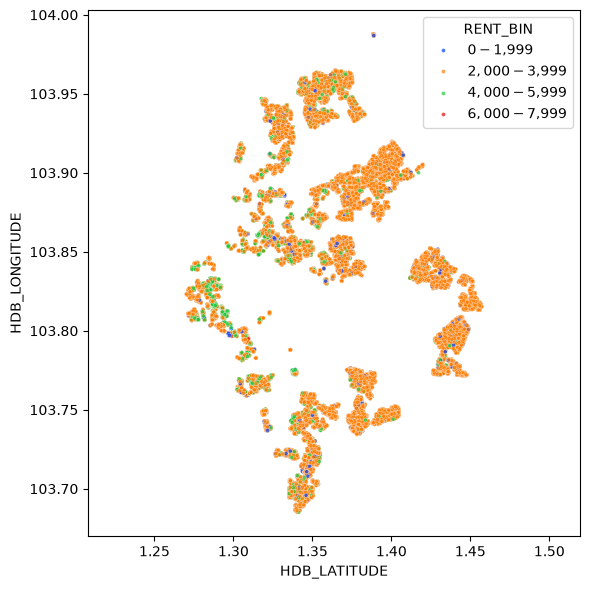

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

bin_size = 2000
train_location = train_location.copy()
train_location["RENT_BIN"] = ((train_location["MONTHLY_RENT"] // bin_size) * bin_size).astype(int)

train_location["RENT_BIN"] = (
    train_location["RENT_BIN"]
    .apply(lambda x: f"${x:,}-${x + bin_size - 1:,}")
)

plt.figure(figsize=(6, 6))

sns.scatterplot(
    data=train_location,
    x="HDB_LATITUDE",
    y="HDB_LONGITUDE",
    hue="RENT_BIN",
    palette="bright",
    alpha=0.7,
    s=8
)
plt.axis("equal")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "locations_by_monthly_rent_bin.png", dpi=300, bbox_inches="tight")
plt.show()

2. HDB_YEAR_COMPLETED' : Contains NaN in train data, not in test. Looks a little similar to lease commence date from the main dataset.

In [15]:
train_location["HDB_YEAR_COMPLETED"].isna().sum()

np.int64(159)

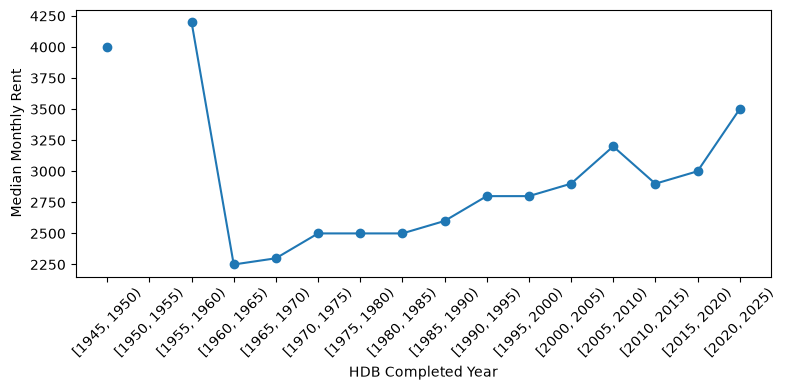

In [16]:
bin_size = 5  # change to 5 for five-year bins
min_year = int(train_location["HDB_YEAR_COMPLETED"].min())
max_year = int(train_location["HDB_YEAR_COMPLETED"].max())

bins = range((min_year // bin_size) * bin_size, ((max_year // bin_size) + 2) * bin_size, bin_size)
train_location["completed_year_bin"] = pd.cut(train_location["HDB_YEAR_COMPLETED"], bins=bins, right=False)
binned_rent = (train_location.groupby("completed_year_bin", observed=False)["MONTHLY_RENT"].median())

plt.figure(figsize=(8, 4))
plt.plot(
    binned_rent.index.astype(str),
    binned_rent.values,
    marker="o"
)
plt.xlabel("HDB Completed Year")
plt.ylabel("Median Monthly Rent")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "monthly_rent_by_completed_year.png", dpi=300, bbox_inches="tight")

3. 'HDB_SUBZONE': Has many unique values, so difficult to plot. Might be a good predictor, like street / town combination.

4. 'HDB_PLANNING_AREA': Looks like TOWN on a high-level.

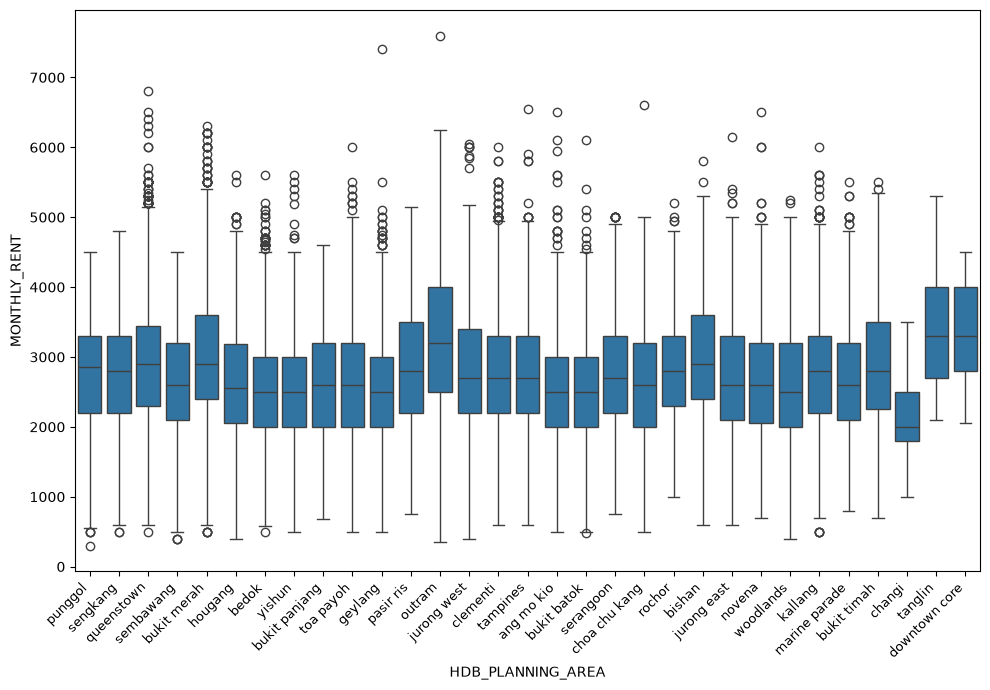

In [17]:
plt.figure(figsize=(10, 7))
sns.boxplot(data=train_location, x="HDB_PLANNING_AREA", y="MONTHLY_RENT")
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "monthly_rent_by_hdb_planning_area.png", dpi=300, bbox_inches="tight")

5. 'NEAREST_MRT_KM', 'NEAREST_SCHOOL_KM', 'NEAREST_MALL_KM': We compute some statistics, and find spearman correlation with the target.

In [18]:
train_location[["NEAREST_MRT_KM", "NEAREST_SCHOOL_KM", "NEAREST_MALL_KM"]].describe()

,NEAREST_MRT_KM,NEAREST_SCHOOL_KM,NEAREST_MALL_KM
count,150000.000000,150000.000000,150000.000000
mean,0.590872,0.345501,0.810214
std,0.326872,0.211975,0.447314
min,0.021845,0.024210,0.000026
25%,0.368029,0.202002,0.462383
50%,0.533265,0.294354,0.732251
75%,0.756433,0.433144,1.083310
max,2.571687,3.309221,3.202447


In [19]:
train_location[["NEAREST_MRT_KM", "MONTHLY_RENT"]].corr(method="spearman")

,NEAREST_MRT_KM,MONTHLY_RENT
NEAREST_MRT_KM,1.000000,-0.085821
MONTHLY_RENT,-0.085821,1.000000


In [20]:
train_location[["NEAREST_MALL_KM", "MONTHLY_RENT"]].corr(method="spearman")

,NEAREST_MALL_KM,MONTHLY_RENT
NEAREST_MALL_KM,1.000000,-0.087941
MONTHLY_RENT,-0.087941,1.000000


In [21]:
train_location[["NEAREST_SCHOOL_KM", "MONTHLY_RENT"]].corr(method="spearman")

,NEAREST_SCHOOL_KM,MONTHLY_RENT
NEAREST_SCHOOL_KM,1.000000,-0.011586
MONTHLY_RENT,-0.011586,1.000000
